# PROTOTYPE: two maps of Congress

**Throwaway prototype, 13 November 2026 (Martin, with Claude). Not the paper, not agreed by the group.**
One run, definitions chosen on the day. It lives on the branch `prototype/two-maps-of-congress`.

**Question.** Is the Congress that members *talk about* on the House floor more or less divided by party
than the Congress that *works together* on bills?

- **Named map:** a tie between two members when one names the other in a floor speech.
- **Working map:** a tie between two members when one cosponsors the other's bill.
- **Measure:** party modularity of each map (how much more the ties stay inside a party than chance
  predicts), against a null where every member keeps their number of ties but the ties are rewired at random.

It reads only `data/processed/` and writes one figure, `figures/prototype_two_maps.png`.

## 0. Every modelling choice in one place

Each of these could have been decided differently. The last column says what the alternative would change.

| # | Choice | Value here | Alternative and what it would change |
|---|---|---|---|
| 1 | Who is a node | The 450 Republicans and Democrats in `members.csv`, including 18 who left or joined mid-Congress | Dropping the 18 removes members with few ties. The one independent in the file is dropped because he has no party side |
| 2 | Which speech text | House floor turns only (`section == "H"`), at least 50 words, as in Anas's pilot | Extensions of Remarks (`"E"`) are written tributes, mostly to constituents. Short turns are mostly procedure |
| 3 | What counts as a name | A title (Mr., Ms., Representative, Chairman, Ranking Member, Speaker, Leader, Whip ...) followed by a surname in `members.csv` | Bare surnames without a title would add mentions and many false hits |
| 4 | Shared surnames (56 members) | Resolved by a first name in the match, else by the member's state within 80 characters, else **dropped**. "Speaker Johnson" is read as Mike Johnson | Anas's pilot dropped all 56. Dropping them hides the Speaker; guessing would add wrong ties |
| 5 | Multi-word surnames (11 members) | Matched on the full surname ("Van Drew", "Wasserman Schultz") | The pilot matched the last word only and lost them |
| 6 | Procedural yields | A mention with "yield" within 60 characters is flagged. The main named map **keeps** them; a second map drops them | Yields go mostly to one's own side, so they push party modularity up |
| 6b | Leadership titles | A mention made with Chairman, Ranking Member, Speaker, Leader or Whip is flagged. A third named map drops these as well as yields | Thanking a committee's chair and ranking member is a floor courtesy that crosses the aisle by design, so it pushes party modularity down |
| 7 | Direction and weight of a named tie | Undirected and unweighted: a tie exists if either names the other at least once | Directed would separate naming from being named. Weighted would let a few floor managers dominate |
| 8 | Which bills | `hr` and `hjres`, withdrawn cosponsorships removed, as in the earlier notebooks | Simple and concurrent resolutions are mostly commemorative |
| 9 | Working tie | Undirected: a tie if either member cosponsored a bill the other sponsored. Weight = number of such bills | Cosponsor-to-cosponsor ties (signing the same third bill) would make the map far denser |
| 10 | Thinning the working map | Three versions: all ties; the disparity-filter backbone at α = 0.05 (as in `martin_blocs.ipynb`); the strongest ties, cut to the same number of ties as the named map | Modularity depends on density, so the dense map and the sparse map cannot be compared directly. The size-matched version is the fair comparison |
| 11 | Ties at the cut-off weight | Broken at random with a fixed seed | A different seed changes which equal-weight ties are kept |
| 12 | The groups | The two parties, fixed in advance. No community detection in this prototype | Louvain would find its own groups and need its own stability check |
| 13 | Null model | Degree-preserving rewiring (double edge swap), 5 swaps per tie, 200 rewirings (20 for the all-ties map, which is slow) | A random graph without fixed degrees would be an easier null to beat |
| 14 | Seed | 2805 | Changes the rewirings, the layout and choice 11 |

**Not validated in this prototype:** the precision and recall of the name matcher. Section 2 prints 30
matches to read by hand.

In [1]:
import re, numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt

DATA, SEED = "data/processed", 2805
MIN_TURN_WORDS = 50               # choice 2
BILL_TYPES     = ("hr", "hjres")  # choice 8
ALPHA          = 0.05             # choice 10: disparity filter
STATE_WINDOW   = 80               # choice 4: characters either side searched for a state name
YIELD_WINDOW   = 60               # choice 6
SWAPS_PER_TIE  = 5                # choice 13
N_REWIRE, N_REWIRE_DENSE = 200, 20
rng = np.random.default_rng(SEED)

members = pd.read_csv(f"{DATA}/members.csv")
members = members[members.party.isin(["R", "D"])].set_index("bioguide")      # choice 1
party, last = members.party, members["last"]
bills      = pd.read_parquet(f"{DATA}/bills.parquet")
cosponsors = pd.read_parquet(f"{DATA}/cosponsors.parquet")
speeches   = pd.read_parquet(f"{DATA}/speeches.parquet")
print("nodes:", party.value_counts().to_dict())

nodes: {'R': 226, 'D': 224}


## 1. The named map: who names whom on the floor

In [2]:
STATES = dict(AL="Alabama", AK="Alaska", AZ="Arizona", AR="Arkansas", CA="California", CO="Colorado", CT="Connecticut",
    DE="Delaware", FL="Florida", GA="Georgia", HI="Hawaii", ID="Idaho", IL="Illinois", IN="Indiana", IA="Iowa", KS="Kansas",
    KY="Kentucky", LA="Louisiana", ME="Maine", MD="Maryland", MA="Massachusetts", MI="Michigan", MN="Minnesota",
    MS="Mississippi", MO="Missouri", MT="Montana", NE="Nebraska", NV="Nevada", NH="New Hampshire", NJ="New Jersey",
    NM="New Mexico", NY="New York", NC="North Carolina", ND="North Dakota", OH="Ohio", OK="Oklahoma", OR="Oregon",
    PA="Pennsylvania", RI="Rhode Island", SC="South Carolina", SD="South Dakota", TN="Tennessee", TX="Texas", UT="Utah",
    VT="Vermont", VA="Virginia", WA="Washington", WV="West Virginia", WI="Wisconsin", WY="Wyoming")

by_last = members.reset_index().groupby("last").bioguide.apply(list).to_dict()      # surname -> members carrying it
SPEAKER = members.index[(last == "Johnson") & (members.state == "LA")][0]           # choice 4
TITLE = r"(Mr\.|Ms\.|Mrs\.|Speaker|Leader|Whip|Representatives?|Rep\.|Congressm[ae]n|Congresswom[ae]n|Chairm[ae]n|Chairwoman|Ranking Member)"
LEADER_TITLES = {"Speaker", "Leader", "Whip", "Chairman", "Chairmen", "Chairwoman", "Ranking Member"}   # choice 6b
RX = re.compile(r"\b" + TITLE + r"\s+((?:[A-Z][A-Za-z'’\-]+\s){0,3}[A-Z][A-Za-z'’\-]+)")

def resolve(title, words, text, a, b):
    """Return (member, how it was resolved) or (None, reason)."""
    words = [w.title() if w.isupper() else w for w in words]
    for n in (3, 2, 1):                                   # longest surname first (choice 5)
        key = " ".join(words[-n:])
        if len(words) >= n and key in by_last:
            cands, before = by_last[key], words[:-n]
            if len(cands) == 1: return cands[0], "unique surname"
            if title == "Speaker" and key == "Johnson": return SPEAKER, "Speaker rule"
            first = [c for c in cands if members.first[c] in before]
            if len(first) == 1: return first[0], "first name"
            near = text[max(0, a - STATE_WINDOW): b + STATE_WINDOW]
            st = [c for c in cands if STATES[members.state[c]] in near]
            if len(st) == 1: return st[0], "state nearby"
            return None, "shared surname, dropped"
    return None, "not a member"

turns = speeches[(speeches.section == "H") & (speeches.n_words >= MIN_TURN_WORDS) & speeches.bioguide.isin(members.index)]
rows, dropped = [], 0
for src, text in zip(turns.bioguide, turns.text):
    for mm in RX.finditer(text):
        who, how = resolve(mm.group(1), mm.group(2).split(), text, mm.start(), mm.end())
        if how == "shared surname, dropped": dropped += 1
        if who is None or who == src: continue
        ctx = text[max(0, mm.start() - YIELD_WINDOW): mm.end() + YIELD_WINDOW]
        rows.append((src, who, how, "yield" in ctx.lower(), mm.group(1) in LEADER_TITLES, ctx.replace("\n", " ")))
M = pd.DataFrame(rows, columns=["speaker", "named", "how", "is_yield", "is_leader_title", "context"])
M["cross"] = party[M.speaker].values != party[M.named].values

print(f"turns read: {len(turns):,} from {turns.bioguide.nunique()} speakers, {turns.day.min()} to {turns.day.max()}")
print(f"mentions: {len(M):,} over {M[['speaker','named']].drop_duplicates().shape[0]:,} speaker-named pairs")
print("how each was resolved:", M.how.value_counts().to_dict(), f"| shared-surname mentions dropped: {dropped:,}")
print(f"flagged as near a yield: {M.is_yield.mean():.0%} | across parties: {M.cross.mean():.0%} of all, {M[~M.is_yield].cross.mean():.0%} without yields")
print(f"named with a leadership title (Chairman, Ranking Member, Speaker, Leader, Whip): {M.is_leader_title.mean():.0%}")
print("most named:", [(last[k], int(v)) for k, v in M.named.value_counts().head(8).items()])

turns read: 17,579 from 442 speakers, 2025-01-06 to 2026-11-09
mentions: 7,931 over 4,491 speaker-named pairs
how each was resolved: {'unique surname': 7166, 'state nearby': 361, 'Speaker rule': 234, 'first name': 170} | shared-surname mentions dropped: 717
flagged as near a yield: 18% | across parties: 36% of all, 42% without yields
named with a leadership title (Chairman, Ranking Member, Speaker, Leader, Whip): 20%
most named: [('Johnson', 239), ('Hill', 161), ('McGovern', 147), ('Mills', 116), ('Cole', 106), ('Westerman', 103), ('Roy', 98), ('Waters', 81)]


## 2. Read these by hand

Thirty random matches. For each: does the name point at the right member, and is it a real reference or
procedure? This is the only check on the matcher so far, and nobody has counted it yet.

In [3]:
for r in M.sample(30, random_state=SEED).itertuples():
    tag = ("yield " if r.is_yield else "") + r.how
    print(f"[{last[r.speaker]} ({party[r.speaker]}) -> {members.name[r.named]} ({party[r.named]}, {members.state[r.named]}) | {tag}]\n   …{r.context}…")

[Alford (R) -> Rosa L. DeLauro (D, CT) | unique surname]
   …Mr. Speaker, I thank Chairman Cole and Ranking Member DeLauro for their hard work in this endeavor. Mr. Speaker, here we …
[DeLauro (D) -> Tom Cole (R, OK) | unique surname]
   …ore the conclusion of this continuing resolution. I believe Chairman Cole, Vice Chair Murray, and Chair Collins share this commitment…
[Roy (R) -> Keith Self (R, TX) | yield unique surname]
   …he Bible. Mr. Speaker, I yield to the gentleman from Texas (Mr. Self) to celebrate our good friend Tim Reitz.…
[Dean (D) -> Frank Pallone, Jr. (D, NJ) | unique surname]
   …Mr. Speaker, I thank Ranking Member Pallone for this opportunity to talk about the Sunshine Protection …
[Fine (R) -> Scott H. Peters (D, CA) | unique surname]
   …l District. Investing into our future farmers and ranchers, Mrs. Peters now holds classes showing students how to raise, breed, and…
[Nunn (R) -> J. French Hill (R, AR) | unique surname]
   …Mr. Speaker, I thank Chairman Hill for 

## 3. The working map, and the thinned versions

In [4]:
def graph(pairs, weights=None):
    """Undirected graph on all 450 members from a list of (a, b) pairs; weight = number of times the pair occurs."""
    df = pd.DataFrame({"a": np.minimum(pairs[0], pairs[1]), "b": np.maximum(pairs[0], pairs[1])}).value_counts()
    G = nx.Graph(); G.add_nodes_from(members.index)
    G.add_weighted_edges_from((a, b, int(w)) for (a, b), w in df.items())
    return G

def backbone(G, alpha):
    """Disparity filter, as in martin_blocs.ipynb: keep a tie if it is surprisingly strong for either member."""
    H = nx.Graph(); H.add_nodes_from(G)
    for u in G:
        k, s = G.degree(u), G.degree(u, weight="weight")
        if k < 2: continue
        for v in G[u]:
            if (1 - G[u][v]["weight"] / s) ** (k - 1) < alpha: H.add_edge(u, v, weight=G[u][v]["weight"])
    return H

def strongest(G, n):
    """The n strongest ties; ties at the cut-off weight are broken at random (choice 11)."""
    e = pd.DataFrame([(u, v, d["weight"]) for u, v, d in G.edges(data=True)], columns=["u", "v", "w"])
    e = e.assign(r=rng.random(len(e))).sort_values(["w", "r"], ascending=False).head(n)
    H = nx.Graph(); H.add_nodes_from(G); H.add_weighted_edges_from(e[["u", "v", "w"]].itertuples(index=False))
    return H, int(e.w.min())

named     = graph((M.speaker.values, M.named.values))
named_ny  = graph((M[~M.is_yield].speaker.values, M[~M.is_yield].named.values))
plain     = M[~M.is_yield & ~M.is_leader_title]
named_pl  = graph((plain.speaker.values, plain.named.values))

b = bills[bills.type.isin(BILL_TYPES)]
links = cosponsors[~cosponsors.withdrawn].merge(b[["bill_id", "sponsor"]], on="bill_id")
links = links[links.cosponsor.isin(members.index) & links.sponsor.isin(members.index) & (links.cosponsor != links.sponsor)]
work      = graph((links.cosponsor.values, links.sponsor.values))
work_bb   = backbone(work, ALPHA)
work_top, cut    = strongest(work, named.number_of_edges())
work_top_ny, cut_ny = strongest(work, named_ny.number_of_edges())
print(f"cosponsorships used: {len(links):,} on {links.bill_id.nunique():,} bills")
print(f"size-matched working maps keep ties on at least {cut} bills (matched to named) and {cut_ny} bills (matched to named without yields)")

LAYERS = {
    "Named on the floor":                  named,
    "Named on the floor, yields dropped":  named_ny,
    "Named, yields and leadership titles dropped": named_pl,
    "Working: all ties":                   work,
    "Working: backbone α = 0.05":          work_bb,
    "Working: strongest, same size as named":               work_top,
    "Working: strongest, same size as named without yields": work_top_ny,
}
for k, G in LAYERS.items():
    print(f"{k:55s} {sum(d > 0 for _, d in G.degree()):3d} members with a tie, {G.number_of_edges():6,} ties, density {nx.density(G):.3f}")

cosponsorships used: 126,475 on 8,701 bills
size-matched working maps keep ties on at least 6 bills (matched to named) and 7 bills (matched to named without yields)
Named on the floor                                      441 members with a tie,  3,718 ties, density 0.037
Named on the floor, yields dropped                      440 members with a tie,  3,249 ties, density 0.032
Named, yields and leadership titles dropped             436 members with a tie,  2,717 ties, density 0.027
Working: all ties                                       449 members with a tie, 46,513 ties, density 0.460
Working: backbone α = 0.05                              438 members with a tie,  2,328 ties, density 0.023
Working: strongest, same size as named                  409 members with a tie,  3,718 ties, density 0.037
Working: strongest, same size as named without yields   402 members with a tie,  3,249 ties, density 0.032


## 4. Party modularity against the rewired null

- **Party modularity Q:** the share of ties inside a party minus the share expected from the members'
  numbers of ties. Zero means party does not matter; higher means more divided.
- **Cross-party share:** the plain share of ties that join a Republican and a Democrat, and the same
  share after rewiring. Their ratio is the easiest number to compare between maps of different size.

In [5]:
SIDES = [set(party.index[party == "R"]), set(party.index[party == "D"])]

def stats(G):
    cross = np.mean([party[u] != party[v] for u, v in G.edges()])
    return nx.community.modularity(G, SIDES, weight=None), cross

def rewired(G, n):
    out, m = [], G.number_of_edges()
    for s in range(n):
        R = G.copy()
        nx.double_edge_swap(R, nswap=SWAPS_PER_TIE * m, max_tries=200 * SWAPS_PER_TIE * m, seed=SEED + s)
        out.append(stats(R))
    return np.array(out)

rows, NULLS = [], {}
for name, G in LAYERS.items():
    q, cross = stats(G)
    null = rewired(G, N_REWIRE_DENSE if G is work else N_REWIRE); NULLS[name] = null
    rows.append({"map": name, "ties": G.number_of_edges(), "cross-party share": cross, "after rewiring": null[:, 1].mean(),
                 "ratio": cross / null[:, 1].mean(), "party Q": q, "null Q": null[:, 0].mean(), "null sd": null[:, 0].std(),
                 "null max": null[:, 0].max(), "z": (q - null[:, 0].mean()) / null[:, 0].std(), "rewirings": len(null)})
T = pd.DataFrame(rows).set_index("map")
print(T.round(3).to_string())

                                                        ties  cross-party share  after rewiring  ratio  party Q  null Q  null sd  null max        z  rewirings
map                                                                                                                                                           
Named on the floor                                      3718              0.345           0.500  0.689    0.154  -0.002    0.008     0.022   20.446        200
Named on the floor, yields dropped                      3249              0.384           0.499  0.770    0.113  -0.001    0.008     0.021   14.350        200
Named, yields and leadership titles dropped             2717              0.392           0.502  0.780    0.107  -0.003    0.010     0.026   10.810        200
Working: all ties                                      46513              0.287           0.497  0.577    0.210   0.000    0.001     0.003  150.202         20
Working: backbone α = 0.05                    

## 5. The figure

Top row: the two maps at the same number of ties, drawn with the same layout method (spring layout, seed
2805) and coloured by party. Only the largest connected piece of each map is drawn. Bottom: party modularity of
every map (dot) against its rewired null (bar from the smallest to the largest rewiring).

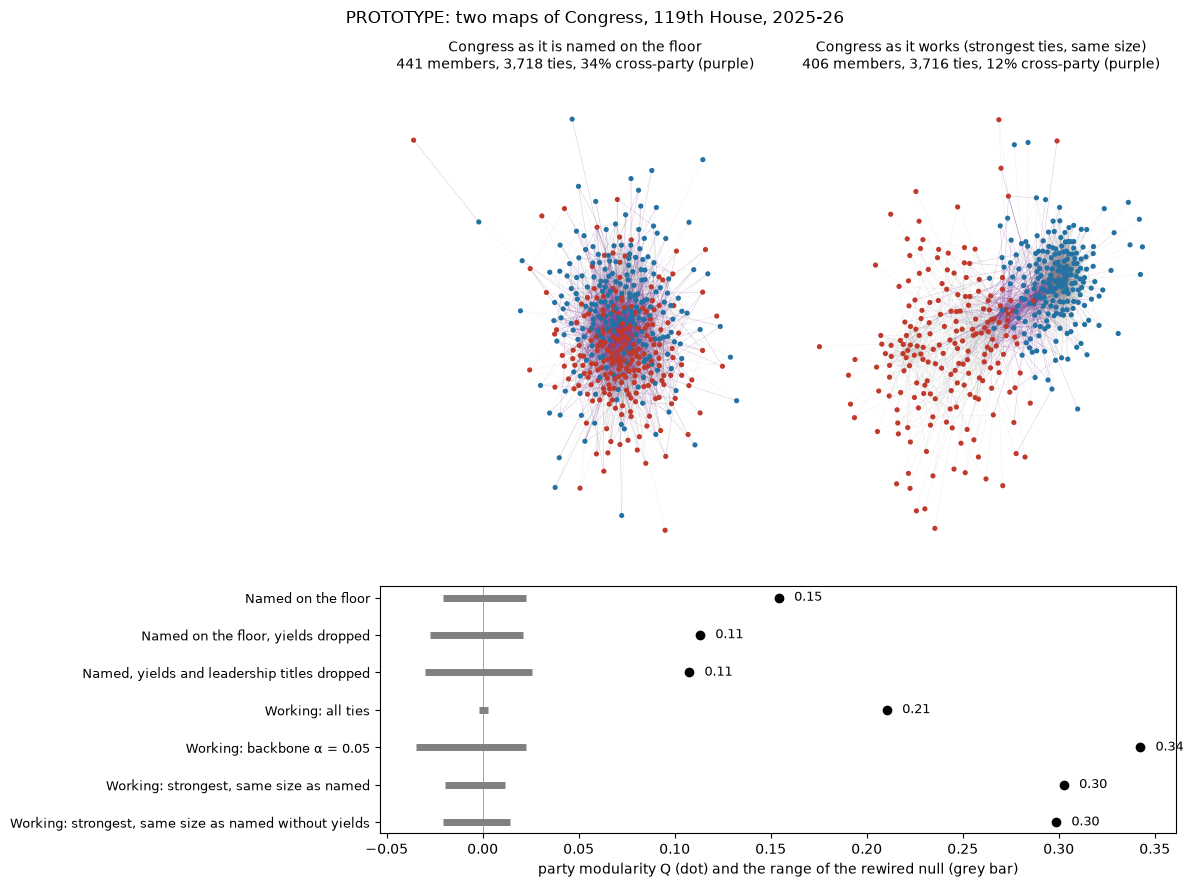

In [6]:
COL = {"R": "#c0392b", "D": "#2471a3"}
fig = plt.figure(figsize=(12, 9)); gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.5])
for i, (title, G) in enumerate([("Congress as it is named on the floor", named), ("Congress as it works (strongest ties, same size)", work_top)]):
    ax = fig.add_subplot(gs[0, i]); H = G.subgraph(max(nx.connected_components(G), key=len))   # largest connected piece only
    pos = nx.spring_layout(H, seed=SEED, k=0.25, iterations=200)
    same = [(u, v) for u, v in H.edges() if party[u] == party[v]]; cross = [(u, v) for u, v in H.edges() if party[u] != party[v]]
    nx.draw_networkx_edges(H, pos, edgelist=same, ax=ax, width=0.3, alpha=0.15, edge_color="grey")
    nx.draw_networkx_edges(H, pos, edgelist=cross, ax=ax, width=0.3, alpha=0.35, edge_color="#7d3c98")
    nx.draw_networkx_nodes(H, pos, ax=ax, node_size=14, node_color=[COL[party[n]] for n in H], linewidths=0)
    ax.set_title(f"{title}\n{H.number_of_nodes()} members, {H.number_of_edges():,} ties, {len(cross)/H.number_of_edges():.0%} cross-party (purple)", fontsize=10)
    ax.axis("off")
ax = fig.add_subplot(gs[1, :]); names = list(LAYERS)[::-1]
for y, n in enumerate(names):
    q = NULLS[n][:, 0]
    ax.plot([q.min(), q.max()], [y, y], color="grey", lw=5, solid_capstyle="butt")
    ax.plot(T.loc[n, "party Q"], y, "o", color="black")
    ax.text(T.loc[n, "party Q"] + 0.008, y, f"{T.loc[n, 'party Q']:.2f}", va="center", fontsize=9)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=9); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("party modularity Q (dot) and the range of the rewired null (grey bar)")
fig.suptitle("PROTOTYPE: two maps of Congress, 119th House, 2025-26", fontsize=12); fig.tight_layout()
fig.savefig("figures/prototype_two_maps.png", dpi=150); plt.show()

## 6. What this run shows, and what it does not

**One run, 13 November 2026. Observations, not results.**

**The named map is much less divided by party than the working map.**

| Map | Ties | Cross-party share | Expected after rewiring | Party Q |
|---|---|---|---|---|
| Named on the floor | 3,718 | 34% | 50% | 0.15 |
| Named, yields dropped | 3,249 | 38% | 50% | 0.11 |
| Named, yields and leadership titles dropped | 2,717 | 39% | 50% | 0.11 |
| Working, strongest ties, same size as named | 3,718 | 12% | 43% | 0.30 |
| Working, backbone α = 0.05 | 2,328 | 15% | 49% | 0.34 |
| Working, all ties | 46,513 | 29% | 50% | 0.21 |

- Every map is more divided than its rewired null. The largest Q in any rewiring is 0.03.
- At the same number of ties, about one named tie in three crosses the aisle, against about one working
  tie in eight.
- Dropping yields makes the named map *less* divided, as expected: yields go to one's own side.
- Dropping mentions made with a leadership title (20% of mentions) barely changes it. So the low division
  of the named map is not only members thanking the chair and the ranking member.

**What each measurement captures and misses**

- **A named tie** captures that one member referred to another on the floor. It misses the tone. Members
  name opponents to disagree with them ("I cannot agree with Chairman Cole" is in the sample above), so a
  cross-party named tie is not cooperation. This alone could explain the result.
- **A working tie** captures that one member signed the other's bill. Keeping only the strongest ties
  (six bills or more) selects close allies, who are mostly in the same party. The all-ties map sits
  between the two (Q = 0.21), so part of the gap comes from this thinning choice.
- **Party Q** is not comparable between maps of different density. Compare the size-matched pair, or the
  ratio of the cross-party share to its rewired value.

**Not checked**

- **The name matcher.** The 30 matches in section 2 have not been counted. One of them is a clear false
  hit: "Mrs. Peters", a constituent, matched to Scott Peters. 717 shared-surname mentions were dropped.
- **Debate structure.** Floor debate puts a majority and a minority manager in the same exchange. A null
  that keeps who spoke in the same debate fixed would be a harder test than rewiring.
- **Louvain communities** on either map, and their overlap. This prototype uses the two parties only.
- **The floor is not voter-facing.** This is the Washington layer. It does not answer what members show
  their voters.

**The next test that would decide it:** hand-label a sample of cross-party named ties as agreeing,
disagreeing or procedural. If most are disagreement, the headline is "members talk across the aisle to
argue", not "the talked-about Congress is less divided".